In [1]:
from scipy.ndimage import maximum_filter1d
import numpy as np
from numpy import linspace, exp, sin, log, log10, pi
import matplotlib.pyplot as plt
plt.rc('font', size=18) # controls default text sizes

### This notebook reproduces **Figure 3(a, b)** of [Completeness and orthogonahty of qnaslnormal modes xn leaky optical cavities](https://journals.aps.org/pra/pdf/10.1103/PhysRevA.49.3057?casa_token=hOEIbKO0zwQAAAAA%3ATmzmsDQEjJIvuR9iwQjFrBaa5o4ylAZzmKHZstBRbkmMSFpIqpV-wFIwAykoAQ8WOOyfLSS6sCyRZg). In the below, with a few exceptions, we use the notation of this paper.

### We first find the dispersion relation. The quasinormal mode must be of the form $\sin(kx)$ for $x<a$ and $\sin(ka)\exp(ikx)/\exp(ika)$ for $x>a$. In addition, we must have, due to the delta function of **Equation 2.3** of the paper: $i\sin(ka)-\cos(ka)=-Mk\sin(ka)\rightarrow \exp(-ika)=Mk\sin(ka)\rightarrow 1-(M/a)(ka)\exp(ika)\sin(ka)=0$. This is precisely the condition that **Equation 4.2(b)** of the paper vanish. Note that we use $k$ instead of $\omega$ to clarify that we are dealing with wavenumbers and not frequencies. 

### For large values of $M/a$, there is clearly a root near $ka=0$. To lowest order in $(M/a)$, this root may be found by expanding the dispersion relation to give $1-(M/a)(ka)^2\approx 0\rightarrow (ka)\approx \pm\sqrt{M/a}$. At one higher order, the dispersion relation becomes $1-(M/a)(ka)^2-i(M/a)(ka)^3$. If we set $(ka)\approx \pm \sqrt{(M/a)}+\Delta$, we obtain, to first order in $\Delta$, $\mp 2\Delta-i\Big(\pm(M/a)+ 3\Delta \sqrt{M/a}\Big)=0 \rightarrow \Delta = -(i/2)(M/a)$

In [2]:
def dispersion_relation(m_over_a, ka): # Implements the exact dispersion relation from the cell above 
    return 1-m_over_a*ka*exp(1j*ka)*sin(ka)

### In the below, we find the first $\approx 100$ resonance wavenumbers numerically. However, for higher mode indices, we simply approximate the wavenumbers to lie at values $ma/\pi$, where $a$ is the length of the cavity and $m$ is an integer.

In [3]:
num_real = 5000
num_imag = 5000
real_ka = linspace(0.618, 0.6185, num_real)
imag_ka = linspace(-0.213, -0.2125, num_imag)
ka = real_ka.reshape((num_real, 1)).repeat(num_imag, axis=1)+1j*imag_ka.reshape((1, num_imag)).repeat(num_real, axis=0);
m_over_a = 2 # Taken from the paper. Note that we use lowercase but m is actually M in the notation of the paper.
mode_condition = dispersion_relation(m_over_a, ka);
mode_heatmap_data = log(np.abs(mode_condition))
first_mode_idx = mode_heatmap_data.argmin();
first_ka_j = ka.flatten()[first_mode_idx]

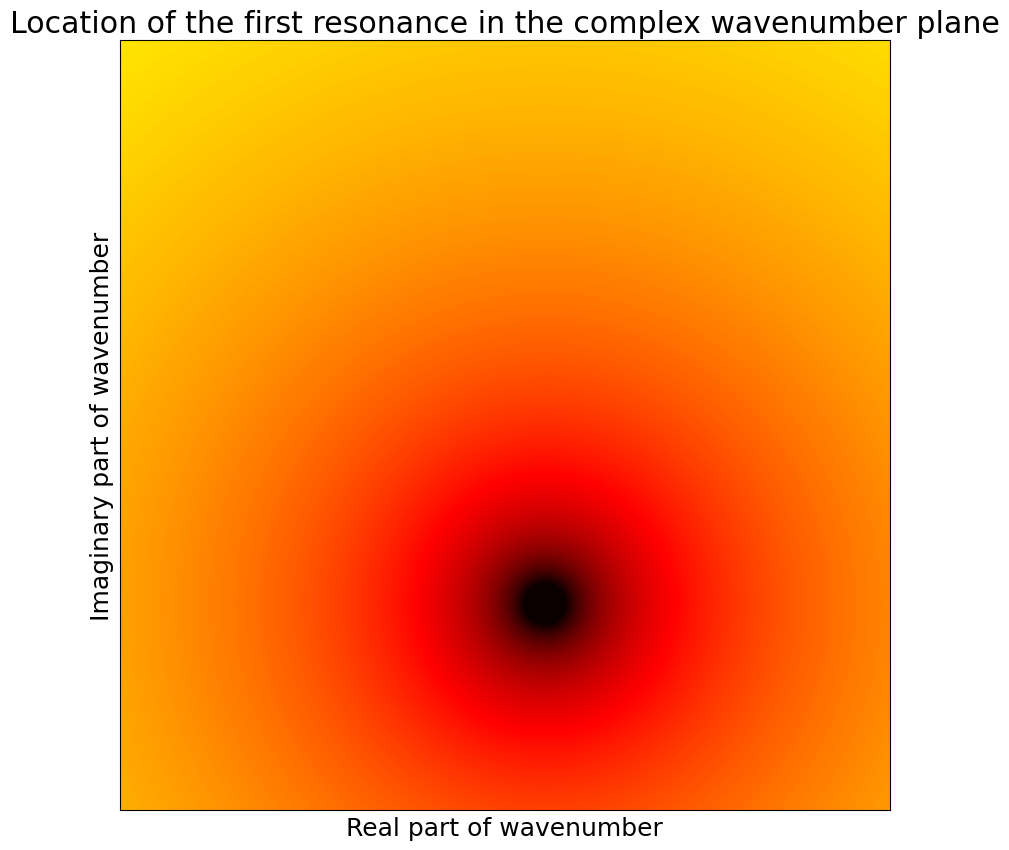

In [4]:
fig, ax = plt.subplots(figsize=(10, 10))
ax.imshow(mode_heatmap_data.T, cmap="hot", origin="lower", vmax=-5, vmin=-10);
ax.set_xticks([]);
ax.set_yticks([]);
ax.set_title("Location of the first resonance in the complex wavenumber plane")
ax.set_xlabel("Real part of wavenumber");
ax.set_ylabel("Imaginary part of wavenumber");

In [6]:
ka_j_v = [] # List to hold the locations of the first ~100 resonances
ka_j_v.append(first_ka_j)
for j in range(1, 101):
    if (j % 10) == 0:
        print(f"j={j}");
        print(f"ka_j: {ka_j}");

    real_ka = linspace(j*pi-2e-1, j*pi+2e-1, num_real)
    imag_ka = linspace(-0.03, 0, num_imag)
    ka = real_ka.reshape((num_real, 1)).repeat(num_imag, axis=1)+1j*imag_ka.reshape((1, num_imag)).repeat(num_real, axis=0);
    mode_condition = dispersion_relation(m_over_a, ka);
    mode_heatmap_data = log(np.abs(mode_condition))
    mode_idx = mode_heatmap_data.argmin();
    ka_j = ka.flatten()[mode_idx]
    ka_j_v.append(ka_j)    

j=10
ka_j: (28.291977411013878-0.0003120624124824979j)
j=20
ka_j: (59.69862209054053-7.201440288057831e-05j)
j=30
ka_j: (91.11166805032325-3.0006001200240384e-05j)
j=40
ka_j: (122.52615429816356-1.8003600720146312e-05j)
j=50
ka_j: (153.94128067402949-1.2002400480097541e-05j)
j=60
ka_j: (185.356647097905-6.001200240048771e-06j)
j=70
ka_j: (216.77217355378696-6.001200240048771e-06j)
j=80
ka_j: (248.1878600416753-6.001200240048771e-06j)
j=90
ka_j: (279.60354652956363-6.001200240048771e-06j)
j=100
ka_j: (311.01931303345515+0j)


### We now implement the norm and the completeness relations defined by **Equation 4.5** and **Equation 4.6** of the paper, respectively. 

In [7]:
def norm(m_over_a, ka_j): # Norm of the resonance state
    a_over_m = 1/m_over_a
    return (ka_j/2)*(1+a_over_m/ka_j/(ka_j+2j*a_over_m)) # note that we have ka_j instead of a as the prefactor
                                                         # this is because we take out a factor of 1/k_j from the function completeness, defined below
def completeness(m_over_a, ka_j, delta_over_a, x_over_a, y_over_a): # One term for the completeness relation for the resonance state
    return sin(ka_j*x_over_a)*sin(ka_j*y_over_a)*sin(ka_j*delta_over_a)/norm(m_over_a, ka_j)

### We now check the completeness relation (**Equation 4.6** of the paper). As a minor digression, note that **Equation 4.6** may be derived from **Equation 4.4** by using the following: $\int_{y-\Delta}^{y+\Delta} \sin(ky')\text{d}y'=\frac{1}{k}\Big(\cos(k(y'-\Delta))-\cos(k(y'+\Delta)) \Big)=\frac{2}{k}\sin(ky)\sin(k\Delta)$

In [8]:
m_over_a = 2 # Taken from the paper. 

x_over_a_v = [0.50, 0.50, 0.30, 0.70] # Taken from caption of Figure 3
y_over_a_v = [0.20, 0.70, 0.25, 0.80] # Taken from caption of Figure 3
delta_over_a_v = [0.10, 0.10, 0.10, 0.20] # Taken from caption of Figure 3

completeness_condition_v_v =[] # Holds data for each of the four curves in Figure 3
for (x_over_a, y_over_a, delta_over_a) in zip(x_over_a_v, y_over_a_v, delta_over_a_v): 
    completeness_condition = 0 
    completeness_condition_v = []
    num_qnms_v = []
    num_qnms = 0
    for ka_j in ka_j_v:
        completeness_condition += completeness(m_over_a, ka_j, delta_over_a, x_over_a, y_over_a)
        completeness_condition += completeness(m_over_a, -np.conj(ka_j), delta_over_a, x_over_a, y_over_a)
        completeness_condition_v.append(completeness_condition)
        num_qnms += 2
        num_qnms_v.append(num_qnms)
    for m in range(101, 1000000):
        ka_j = m*pi # This is a decent approximation for very large mode indices
        completeness_condition += completeness(m_over_a, ka_j, delta_over_a, x_over_a, y_over_a)
        completeness_condition += completeness(m_over_a, -np.conj(ka_j), delta_over_a, x_over_a, y_over_a)
        completeness_condition_v.append(completeness_condition)
        num_qnms += 2
        num_qnms_v.append(num_qnms)
    print(f"Completeness condition: {completeness_condition}")
    completeness_condition_v_v.append(completeness_condition_v)

Completeness condition: (-4.427448077035096e-06+5.3894748100271936e-27j)
Completeness condition: (6.864474844698637e-06+7.794758581754328e-28j)
Completeness condition: (1.00000138423595+1.8689300644137645e-26j)
Completeness condition: (0.9999893225183045+6.328989992217636e-27j)


### In the below, `envelope_v_inside` holds two curves. Each of these corresponds to $y-\Delta<x<y+\Delta$. In contrast, `envelope_v_outside` holds two curves for which either $x<y-\Delta$ or $y+\Delta<x$.

In [9]:
envelope_v_inside = [maximum_filter1d(np.abs(np.real(completeness_condition_v)-1), size=40) for completeness_condition_v in completeness_condition_v_v[2:]]
envelope_v_outside = [maximum_filter1d(np.abs(np.real(completeness_condition_v)), size=50) for completeness_condition_v in completeness_condition_v_v[:2]]

### Below is our version of **Figure 3b**

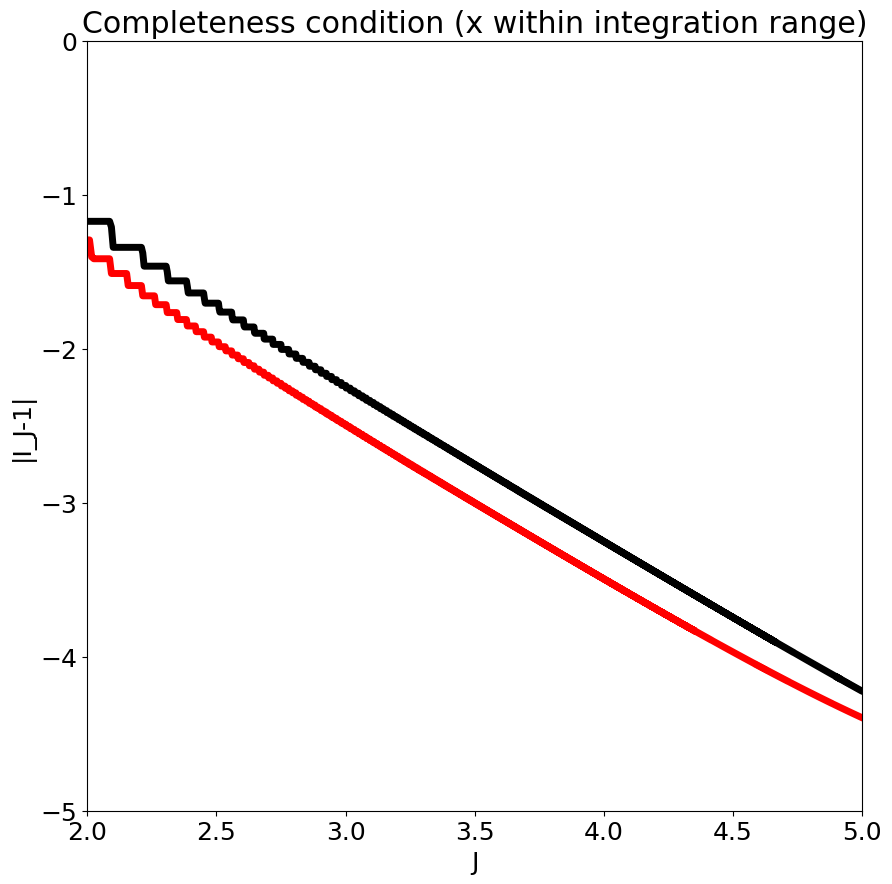

In [20]:
fig, ax = plt.subplots(figsize=(10, 10))
ax.plot(log10(num_qnms_v)[30:], log10(envelope_v_inside[0])[30:], linewidth=5, color="black")
ax.plot(log10(num_qnms_v)[30:], log10(envelope_v_inside[1])[30:], linewidth=5, color="red")
ax.set_xlim(2, 5);
ax.set_ylim(-5, 0);
ax.set_title("Completeness condition (x within integration range)");
ax.set_xlabel("J")
ax.set_ylabel("|I_J-1|");

### Below is our version of **Figure 3a**

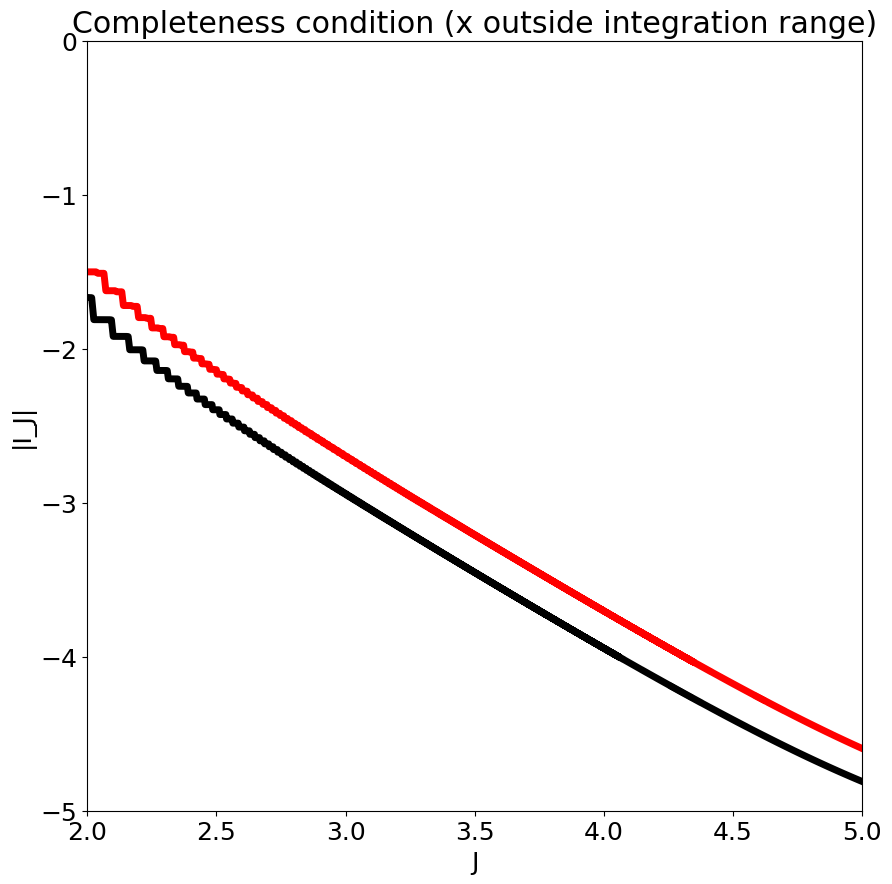

In [18]:
fig, ax = plt.subplots(figsize=(10, 10))
ax.plot(log10(num_qnms_v)[30:], log10(envelope_v_outside[0])[30:], linewidth=5, color="black")
ax.plot(log10(num_qnms_v)[30:], log10(envelope_v_outside[1])[30:], linewidth=5, color="red")
ax.set_xlim(2, 5);
ax.set_ylim(-5, 0);
ax.set_title("Completeness condition (x outside integration range)");
ax.set_xlabel("J")
ax.set_ylabel("|I_J|");